In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import HDBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

iris = load_iris()
X = StandardScaler().fit_transform(iris.data)
y = iris.target

In [2]:
labels = HDBSCAN(min_cluster_size=5, copy=True).fit_predict(X)

n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = (labels == -1).sum()
print('Jumlah cluster :', n_clusters)
print('Jumlah noise   :', n_noise)
print('Adjusted Rand Index:', adjusted_rand_score(y, labels))
pd.crosstab(pd.Series(y, name='Label asli'), pd.Series(labels, name='Cluster HDBSCAN'))

Jumlah cluster : 2
Jumlah noise   : 2
Adjusted Rand Index: 0.5637510205230709


Cluster HDBSCAN,-1,0,1
Label asli,,,
0,0,50,0
1,0,0,50
2,2,0,48


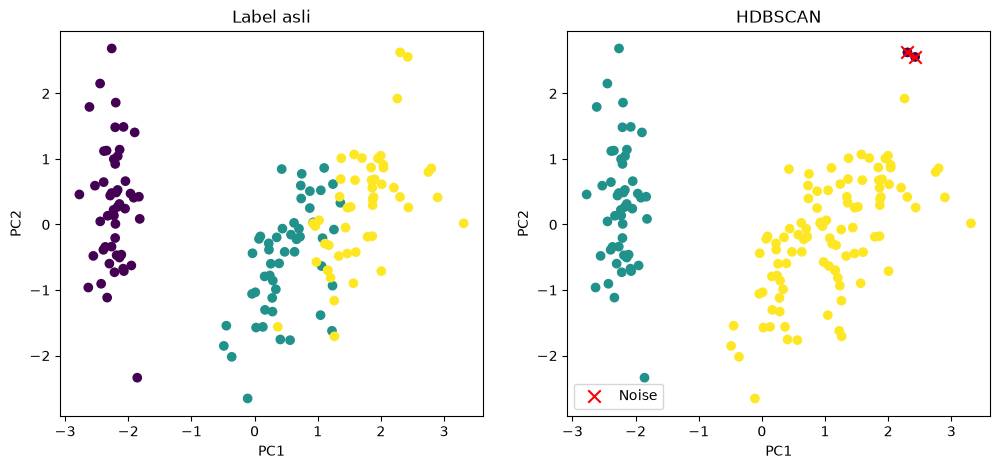

In [3]:
X2 = PCA(n_components=2).fit_transform(X)
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].scatter(X2[:, 0], X2[:, 1], c=y, cmap='viridis')
ax[0].set_title('Label asli')
ax[1].scatter(X2[:, 0], X2[:, 1], c=labels, cmap='viridis')
ax[1].scatter(X2[labels == -1, 0], X2[labels == -1, 1], c='red', marker='x', s=80, label='Noise')
ax[1].set_title('HDBSCAN'); ax[1].legend()
for a in ax: a.set_xlabel('PC1'); a.set_ylabel('PC2')
plt.show()

## Analisis
- HDBSCAN min_cluster_size=5 pada Iris membentuk 2 cluster dengan 2 noise.
- Setosa terpisah sempurna (50 data jadi satu cluster).
- Versicolor dan Virginica menyatu dalam satu cluster karena kedua spesies saling tumpang tindih dan tidak ada celah kepadatan di antaranya. Dua data Virginica menjadi noise.
- Adjusted Rand Index ≈ 0,56: hasil sebagian sesuai dengan label asli (3 spesies), tetapi HDBSCAN hanya menemukan struktur berbasis kepadatan, yaitu 2 kelompok.